# Classification Threshold — C4/V1/s44/QAT INT8

**Mục tiêu:** chọn hai ngưỡng `LOW/HIGH` trên **Validation** cho đầu ra `p_non_asthma` (`Asthma=0`, `Non-Asthma=1`). Không train lại, không chỉnh DSP/VAD.

| Quy tắc | Kết quả |
|---|---|
| `p_non_asthma <= LOW` | `ASTHMA` |
| `LOW < p_non_asthma < HIGH` | `UNSURE` |
| `p_non_asthma >= HIGH` | `NON_ASTHMA` |

**Thứ tự:** Validation → so sánh và chọn ngưỡng → `FROZEN` → Test lịch sử. Tập Test đã được xem xét khi chọn model trước đây, nên không phải đánh giá hoàn toàn độc lập.


In [19]:
from pathlib import Path
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXPERIMENT_RELATIVE = Path('Experiments_Benchmarking/Patient_Node/Final_V1_Validation/01_Classification_Threshold')

def find_experiment_dir():
    # Notebook không có __file__; bắt đầu từ cwd rồi dò ngược lên mọi parent.
    start_dir = Path(os.getcwd()).resolve()
    for base_dir in (start_dir, *start_dir.parents):
        if (base_dir / 'threshold_utils.py').is_file():
            return base_dir

        candidate = base_dir / EXPERIMENT_RELATIVE
        if (candidate / 'threshold_utils.py').is_file():
            return candidate.resolve()

    raise FileNotFoundError(
        'Không tìm thấy 01_Classification_Threshold từ cwd: ' + str(start_dir)
    )

EXPERIMENT_DIR = find_experiment_dir()
print('Working directory :', Path(os.getcwd()).resolve())
print('Experiment folder :', EXPERIMENT_DIR)

sys.path.insert(0, str(EXPERIMENT_DIR))

from Generate_Predictions import (
    EXPECTED_MODEL_SHA256, MODEL_ID, WORKSPACE_DIR, generate_predictions,
)
from threshold_utils import (
    annotate_predictions, compare_candidates, compute_metrics,
    export_final_config, load_final_config, load_predictions,
    rank_candidates, threshold_grid_sweep, write_metrics_csv,
)

RESULTS_DIR = EXPERIMENT_DIR / 'results' / MODEL_ID
FIGURES_DIR = EXPERIMENT_DIR / 'figures' / MODEL_ID
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

VAL_CSV = RESULTS_DIR / 'validation_predictions.csv'
VAL_METADATA = RESULTS_DIR / 'validation_predictions_metadata.json'
FINAL_CONFIG = RESULTS_DIR / 'final_threshold.json'
TEST_CSV = RESULTS_DIR / 'test_predictions.csv'


def audit_cached_predictions(split, csv_path, metadata_path):
    """Kiểm tra CSV cache gắn đúng model/split, không âm thầm dùng CSV cũ."""
    if not metadata_path.is_file():
        raise FileNotFoundError(f"Thiếu provenance JSON: {metadata_path}")
    meta = json.loads(metadata_path.read_text(encoding='utf-8'))
    df = load_predictions(csv_path)
    if meta.get('model_sha256') != EXPECTED_MODEL_SHA256:
        raise ValueError(f"Metadata {split} sai SHA của C4 QAT")
    if str(meta.get('split', '')).lower() != split:
        raise ValueError(f"Metadata không thuộc split {split}")
    if int(meta.get('sample_count', -1)) != len(df):
        raise ValueError(f"CSV/metadata {split} khác số lượng mẫu")
    if 'model_sha256' not in df.columns or not df['model_sha256'].eq(EXPECTED_MODEL_SHA256).all():
        raise ValueError(f"Các dòng CSV {split} không gắn đúng model SHA")
    if 'split' not in df.columns or not df['split'].eq(split).all():
        raise ValueError(f"Các dòng CSV không đúng split {split}")
    expected_count = 154 if split == 'val' else 159
    if len(df) != expected_count:
        raise ValueError(f"{split} kỳ vọng {expected_count}, nhận {len(df)}")
    return df, meta


Working directory : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold
Experiment folder : D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold


## 1. Validation và phân bố xác suất

Sử dụng đúng artifact QAT INT8 C4/s44, kiểm tra SHA-256 và 154 mẫu Validation (38 Asthma, 116 Non-Asthma). Nếu chưa có CSV, script tự sinh prediction. Nhóm tên file `__takeNN` có 16 mẫu và có thể khác phân bố với 138 mẫu còn lại; khi xem các mẫu lỗi cần lưu ý yếu tố nguồn ghi, không tự coi hậu tố này là nguồn Playback đã xác minh.


In [20]:
if not VAL_CSV.is_file():
    generate_predictions('val', VAL_CSV)

val_df, val_metadata = audit_cached_predictions('val', VAL_CSV, VAL_METADATA)
print({key: val_metadata.get(key) for key in ('split', 'sample_count', 'model', 'model_sha256', 'feature_contract')})
display(val_df.head(10))
display(val_df.groupby('true_class')['p_non_asthma'].describe())


{'split': 'val', 'sample_count': 154, 'model': 'combo_pre0_mel40_fft2048__V1__s44_QAT_INT8', 'model_sha256': 'd081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0d6d845d3222efc46b9', 'feature_contract': 'Frontend C4: pre=0, mel=40, fft=2048, shape 40x129x1'}


,split,sample_index,file_path,file_name,true_label,true_class,input_scale,input_zero_point,output_scale,output_zero_point,output_int8,p_non_asthma,p_asthma,binary_pred_0_5,binary_class_0_5,binary_correct_0_5,model_sha256
0,val,0,Asthma/val/AST_033__P16WheezingRS_80__take01.wav,AST_033__P16WheezingRS_80__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-107,0.082031,0.917969,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
1,val,1,Asthma/val/AST_033__P16WheezingRS_80__take02.wav,AST_033__P16WheezingRS_80__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-124,0.015625,0.984375,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
2,val,2,Asthma/val/AST_034__P18WheezingIE_89__take01.wav,AST_034__P18WheezingIE_89__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-127,0.003906,0.996094,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
3,val,3,Asthma/val/AST_034__P18WheezingIE_89__take02.wav,AST_034__P18WheezingIE_89__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
4,val,4,Asthma/val/AST_035__P4AsthmaRS_16__take01.wav,AST_035__P4AsthmaRS_16__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,67,0.761719,0.238281,1,Non_Asthma,0,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
5,val,5,Asthma/val/AST_035__P4AsthmaRS_16__take02.wav,AST_035__P4AsthmaRS_16__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-9,0.464844,0.535156,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
6,val,6,Asthma/val/AST_036__P6AsthmaIU_26__take01.wav,AST_036__P6AsthmaIU_26__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,-89,0.152344,0.847656,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
7,val,7,Asthma/val/AST_036__P6AsthmaIU_26__take02.wav,AST_036__P6AsthmaIU_26__take02.wav,0,Asthma,0.003922,-128,0.003906,-128,-99,0.113281,0.886719,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
8,val,8,Asthma/val/P16WheezingIE_77.wav,P16WheezingIE_77.wav,0,Asthma,0.003922,-128,0.003906,-128,-115,0.050781,0.949219,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...
9,val,9,Asthma/val/P16WheezingIU_78.wav,P16WheezingIU_78.wav,0,Asthma,0.003922,-128,0.003906,-128,-128,0.000000,1.000000,0,Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...


,count,mean,std,min,25%,50%,75%,max
true_class,,,,,,,,
Asthma,38.0,0.050267,0.144422,0.000000,0.000000,0.000000,0.014648,0.761719
Non_Asthma,116.0,0.963699,0.111508,0.351562,0.996094,0.996094,0.996094,0.996094


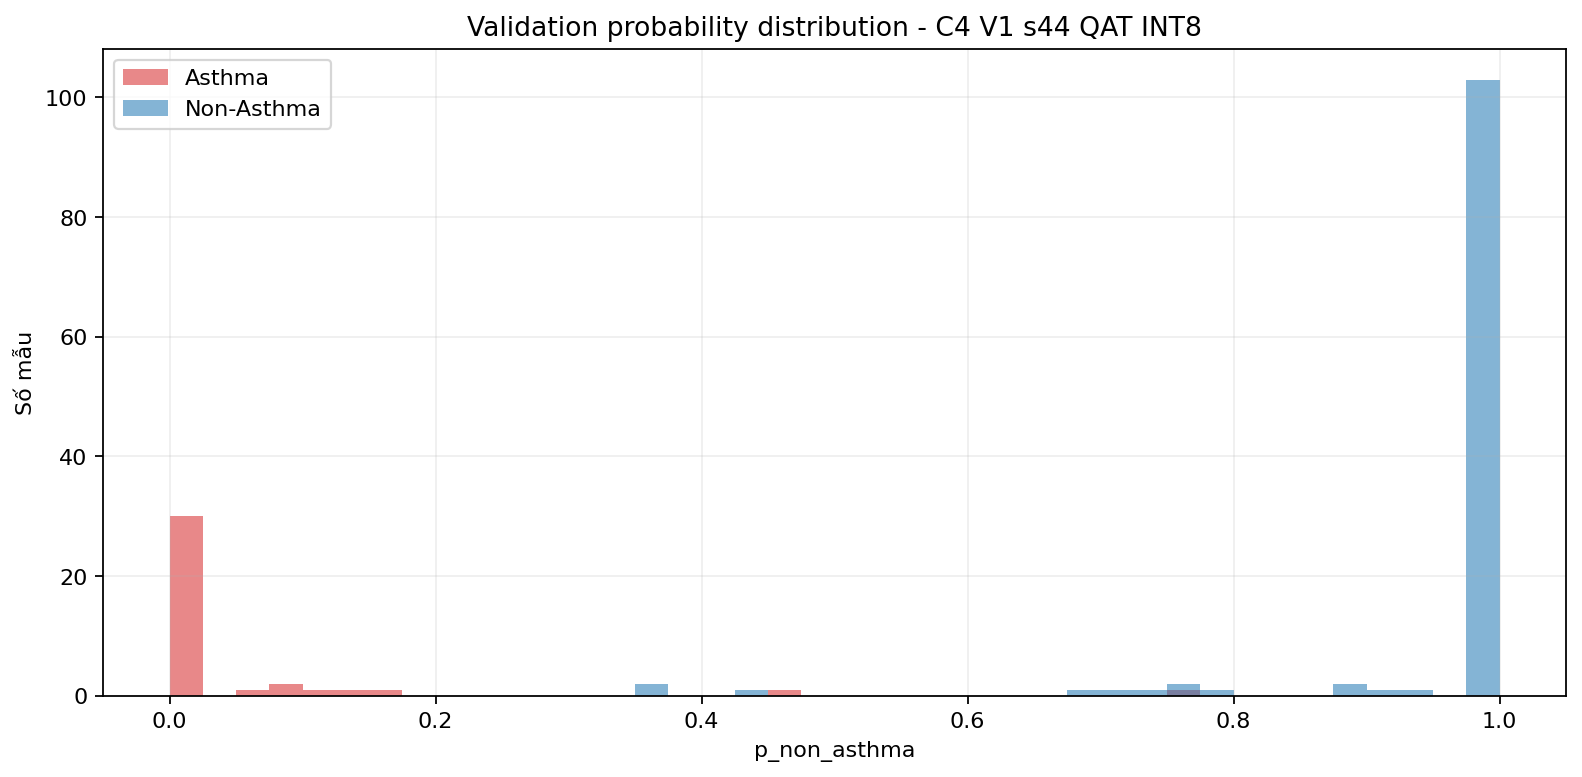

Đã lưu biểu đồ: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold\figures\combo_pre0_mel40_fft2048__V1__s44_QAT_INT8\validation_probability_distribution.png


In [21]:
from IPython.display import Image as IPythonImage, display

fig, ax = plt.subplots(figsize=(10, 5))
for label, color in [(0, 'tab:red'), (1, 'tab:blue')]:
    values = val_df.loc[val_df['true_label'] == label, 'p_non_asthma']
    name = 'Asthma' if label == 0 else 'Non-Asthma'
    ax.hist(values, bins=np.linspace(0, 1, 41), alpha=0.55, label=name, color=color)
ax.set(xlabel='p_non_asthma', ylabel='Số mẫu', title='Validation probability distribution - C4 V1 s44 QAT INT8')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
figure_path = FIGURES_DIR / 'validation_probability_distribution.png'
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(IPythonImage(filename=str(figure_path)))
print('Đã lưu biểu đồ:', figure_path)


## 2. Đối chiếu LOW/HIGH trên Validation

Ưu tiên xem **Asthma → Non-Asthma**, **Non-Asthma → Asthma**, số mẫu `UNSURE` và **coverage** cùng nhau. Hai cặp cần cân nhắc từ kết quả đã chạy:

| LOW / HIGH | Asthma → Non | Non → Asthma | Asthma → UNSURE | Non → UNSURE | Coverage |
|---|---:|---:|---:|---:|---:|
| `0.40 / 0.90` | 0 | **2** | 2 | 9 | 92,86% |
| `0.47 / 0.77` | 0 | 3 | **1** | **4** | **96,75%** |

`UNSURE` không phải dự đoán đúng: ví dụ `0.40/0.90` **không gán nhầm Asthma sang Non-Asthma**, nhưng có 2 mẫu Asthma chưa thể quyết định. Dữ liệu bảng là snapshot từ output Validation của notebook đã tải lên; cell sau có thể tính lại trực tiếp.


In [22]:
CANDIDATES = [
    (0.40, 0.60), (0.45, 0.65), (0.45, 0.70), (0.50, 0.65),
    (0.40, 0.90), (0.43, 0.90), (0.47, 0.77),
]
candidate_df = compare_candidates(val_df, CANDIDATES)
candidate_df.to_csv(RESULTS_DIR / 'candidate_threshold_comparison.csv', index=False, encoding='utf-8-sig')
SHOW = ['low_threshold', 'high_threshold', 'asthma_to_non_asthma',
        'non_asthma_to_asthma', 'asthma_to_unsure', 'non_asthma_to_unsure',
        'coverage', 'accepted_accuracy']
display(candidate_df[SHOW])

,low_threshold,high_threshold,asthma_to_non_asthma,non_asthma_to_asthma,asthma_to_unsure,non_asthma_to_unsure,coverage,accepted_accuracy
0,0.40,0.60,1,2,1,1,0.987013,0.980263
1,0.45,0.65,1,3,1,0,0.993506,0.973856
2,0.45,0.70,1,3,1,1,0.987013,0.973684
3,0.50,0.65,1,3,0,0,1.000000,0.974026
4,0.40,0.90,0,2,2,9,0.928571,0.986014
5,0.43,0.90,0,3,2,8,0.935065,0.979167
6,0.47,0.77,0,3,1,4,0.967532,0.979866


In [23]:
sweep_df = threshold_grid_sweep(val_df)
sweep_df.to_csv(RESULTS_DIR / 'threshold_grid_sweep.csv', index=False, encoding='utf-8-sig')

# Xếp hạng như thuật toán gốc; chỉ hiển thị 8 pattern khác nhau để tránh hàng lặp
ranked_df = rank_candidates(sweep_df)
unique_df = ranked_df.drop_duplicates('decision_pattern_sha256')
display(unique_df.head(8)[SHOW])

,low_threshold,high_threshold,asthma_to_non_asthma,non_asthma_to_asthma,asthma_to_unsure,non_asthma_to_unsure,coverage,accepted_accuracy
0,0.47,0.77,0,3,1,4,0.967532,0.979866
14,0.47,0.78,0,3,1,5,0.961039,0.979730
28,0.43,0.77,0,3,2,4,0.961039,0.979730
32,0.37,0.77,0,2,2,5,0.954545,0.986395
38,0.47,0.79,0,3,1,6,0.954545,0.979592
178,0.43,0.78,0,3,2,5,0.954545,0.979592
182,0.36,0.77,0,1,2,6,0.948052,0.993151
183,0.37,0.78,0,2,2,6,0.948052,0.986301


In [24]:
# 2.1 — Khảo sát độ nhạy ngưỡng trên Validation (chưa freeze)
# Chỉ xét một số ngưỡng quanh biên quyết định, tránh tối ưu quá mức.
cols = ["low_threshold", "high_threshold", "asthma_to_non_asthma",
        "non_asthma_to_asthma", "asthma_to_unsure", "non_asthma_to_unsure",
        "coverage", "accepted_accuracy"]

low_scan = compare_candidates(val_df, [(x, 0.77) for x in (0.35, 0.36, 0.37, 0.40, 0.43, 0.47)])
high_scan = compare_candidates(val_df, [(0.47, x) for x in (0.762, 0.766, 0.770, 0.774, 0.778, 0.780)])
print("LOW thay đổi — cố định HIGH=0.77:")
display(low_scan[cols])
print("HIGH thay đổi — cố định LOW=0.47:")
display(high_scan[cols])

# Những WAV sát vùng phân loại: cùng p có thể thuộc hai nhãn khác nhau.
p = val_df["p_non_asthma"]
borderline = val_df.loc[
    p.between(0.33, 0.49) | p.between(0.72, 0.79),
    ["file_name", "true_class", "output_int8", "p_non_asthma"]
].sort_values(["p_non_asthma", "true_class"])
print("Các WAV cần kiểm tra gần LOW/HIGH:")
display(borderline)


LOW thay đổi — cố định HIGH=0.77:


,low_threshold,high_threshold,asthma_to_non_asthma,non_asthma_to_asthma,asthma_to_unsure,non_asthma_to_unsure,coverage,accepted_accuracy
0,0.35,0.77,0,0,2,7,0.941558,1.000000
1,0.36,0.77,0,1,2,6,0.948052,0.993151
2,0.37,0.77,0,2,2,5,0.954545,0.986395
3,0.40,0.77,0,2,2,5,0.954545,0.986395
4,0.43,0.77,0,3,2,4,0.961039,0.979730
5,0.47,0.77,0,3,1,4,0.967532,0.979866


HIGH thay đổi — cố định LOW=0.47:


,low_threshold,high_threshold,asthma_to_non_asthma,non_asthma_to_asthma,asthma_to_unsure,non_asthma_to_unsure,coverage,accepted_accuracy
0,0.47,0.762,0,3,1,4,0.967532,0.979866
1,0.47,0.766,0,3,1,4,0.967532,0.979866
2,0.47,0.770,0,3,1,4,0.967532,0.979866
3,0.47,0.774,0,3,1,5,0.961039,0.979730
4,0.47,0.778,0,3,1,5,0.961039,0.979730
5,0.47,0.780,0,3,1,5,0.961039,0.979730


Các WAV cần kiểm tra gần LOW/HIGH:


,file_name,true_class,output_int8,p_non_asthma
82,P19Pneumonia41U.wav,Non_Asthma,-38,0.351562
79,P19Pneumonia24H.wav,Non_Asthma,-34,0.367188
122,P40COPDMc_318.wav,Non_Asthma,-18,0.429688
5,AST_035__P4AsthmaRS_16__take02.wav,Asthma,-9,0.464844
40,COPD_009__P33COPDPr_257__take01.wav,Non_Asthma,61,0.738281
4,AST_035__P4AsthmaRS_16__take01.wav,Asthma,67,0.761719
133,P43COPDPr_339.wav,Non_Asthma,67,0.761719
109,P35COPDMc_280.wav,Non_Asthma,70,0.773438
41,COPD_009__P33COPDPr_257__take02.wav,Non_Asthma,74,0.789062


## 3. Chọn LOW/HIGH và kiểm tra mẫu chưa quyết định

Điền **một cặp** vào cell kế tiếp sau khi đọc bảng Validation và xem các file bị gán sai/UNSURE. `None` là chủ ý: **chưa chọn ngưỡng**, nên cell sẽ dừng. Không sử dụng Test để điều chỉnh cặp ngưỡng.


In [25]:
FINAL_LOW = 0.47
FINAL_HIGH = 0.77

SELECTION_RATIONALE = (
    "Chon tren Validation: khong co Asthma -> Non-Asthma, "
    "uu tien giam UNSURE va tang coverage. "
    "Chap nhan 3 Non-Asthma -> Asthma tren 116 mau Non-Asthma. "
    "Khong su dung Test de chon nguong."
)

if FINAL_LOW is None or FINAL_HIGH is None:
    raise ValueError('Hãy quyết định FINAL_LOW/FINAL_HIGH dựa trên bảng Validation trước khi export')
if not SELECTION_RATIONALE.strip():
    raise ValueError('Cần ghi lý do lựa chọn ngưỡng')

final_val_metrics = compute_metrics(
    val_df['true_label'].to_numpy(),
    val_df['p_non_asthma'].to_numpy(),
    FINAL_LOW, FINAL_HIGH,
)
display(pd.DataFrame([final_val_metrics]))

val_annotated = annotate_predictions(val_df, FINAL_LOW, FINAL_HIGH)
display(val_annotated[val_annotated['final_correct'] != 'CORRECT'])

correct = final_val_metrics['asthma_to_asthma'] + final_val_metrics['non_asthma_to_non_asthma']
wrong = final_val_metrics['asthma_to_non_asthma'] + final_val_metrics['non_asthma_to_asthma']
unsure = final_val_metrics['asthma_to_unsure'] + final_val_metrics['non_asthma_to_unsure']
SELECTION_NOTE = (
    f'Selection split=Validation, n={final_val_metrics["total"]}. '
    f'LOW={FINAL_LOW:.6g}, HIGH={FINAL_HIGH:.6g}. '
    f'Correct={correct}, wrong={wrong}, UNSURE={unsure}. '
    f'Coverage={final_val_metrics["coverage"]:.4%}, '
    f'accepted accuracy={final_val_metrics["accepted_accuracy"]:.4%}, '
    f'Asthma -> Non-Asthma={final_val_metrics["asthma_to_non_asthma"]}, '
    f'Non-Asthma -> Asthma={final_val_metrics["non_asthma_to_asthma"]}. '
    + SELECTION_RATIONALE
)
print(SELECTION_NOTE)


,low_threshold,high_threshold,total,asthma_total,non_asthma_total,asthma_to_asthma,asthma_to_unsure,asthma_to_non_asthma,non_asthma_to_asthma,non_asthma_to_unsure,...,asthma_f1,asthma_miss_rate,asthma_unsure_rate,non_asthma_false_alarm_rate,non_asthma_unsure_rate,overall_unsure_rate,coverage,accepted_accuracy,strict_accuracy,decision_pattern_sha256
0,0.47,0.77,154,38,116,37,1,0,3,4,...,0.948718,0.0,0.026316,0.025862,0.034483,0.032468,0.967532,0.979866,0.948052,9bad5db29dd3c2554709267b09b10913efd66c107435f3...


,split,sample_index,file_path,file_name,true_label,true_class,input_scale,input_zero_point,output_scale,output_zero_point,output_int8,p_non_asthma,p_asthma,binary_pred_0_5,binary_class_0_5,binary_correct_0_5,model_sha256,final_predicted_label,final_predicted_class,final_correct
4,val,4,Asthma/val/AST_035__P4AsthmaRS_16__take01.wav,AST_035__P4AsthmaRS_16__take01.wav,0,Asthma,0.003922,-128,0.003906,-128,67,0.761719,0.238281,1,Non_Asthma,0,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,2,UNSURE,UNSURE
40,val,40,Non_Asthma_Disease/val/COPD_009__P33COPDPr_257...,COPD_009__P33COPDPr_257__take01.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,61,0.738281,0.261719,1,Non_Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,2,UNSURE,UNSURE
79,val,79,Non_Asthma_Disease/val/P19Pneumonia24H.wav,P19Pneumonia24H.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,-34,0.367188,0.632812,0,Asthma,0,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,0,ASTHMA,WRONG
82,val,82,Non_Asthma_Disease/val/P19Pneumonia41U.wav,P19Pneumonia41U.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,-38,0.351562,0.648438,0,Asthma,0,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,0,ASTHMA,WRONG
122,val,122,Non_Asthma_Disease/val/P40COPDMc_318.wav,P40COPDMc_318.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,-18,0.429688,0.570312,0,Asthma,0,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,0,ASTHMA,WRONG
123,val,123,Non_Asthma_Disease/val/P40COPDMc_320.wav,P40COPDMc_320.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,50,0.695312,0.304688,1,Non_Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,2,UNSURE,UNSURE
133,val,133,Non_Asthma_Disease/val/P43COPDPr_339.wav,P43COPDPr_339.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,67,0.761719,0.238281,1,Non_Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,2,UNSURE,UNSURE
138,val,138,Non_Asthma_Disease/val/P6Healthy51S.wav,P6Healthy51S.wav,1,Non_Asthma,0.003922,-128,0.003906,-128,54,0.710938,0.289062,1,Non_Asthma,1,d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0...,2,UNSURE,UNSURE


Selection split=Validation, n=154. LOW=0.47, HIGH=0.77. Correct=146, wrong=3, UNSURE=5. Coverage=96.7532%, accepted accuracy=97.9866%, Asthma -> Non-Asthma=0, Non-Asthma -> Asthma=3. Chon tren Validation: khong co Asthma -> Non-Asthma, uu tien giam UNSURE va tang coverage. Chap nhan 3 Non-Asthma -> Asthma tren 116 mau Non-Asthma. Khong su dung Test de chon nguong.


## 4. Freeze ngưỡng

Chỉ chạy sau khi cell 3 đã thành công. `final_threshold.json` khóa LOW/HIGH cùng SHA model và hai ngưỡng raw INT8 dùng trên ESP32-S3. Không thay đổi quyết định sau khi xem Test.


In [26]:
val_annotated.to_csv(RESULTS_DIR / 'validation_predictions_final.csv', index=False, encoding='utf-8-sig')
config_path = export_final_config(
    FINAL_CONFIG,
    FINAL_LOW, FINAL_HIGH,
    final_val_metrics,
    val_metadata,
    SELECTION_NOTE,
)
print(config_path.read_text(encoding='utf-8'))


{
  "status": "FROZEN",
  "experiment": "Patient_Node_Final_V1_Classification_Threshold",
  "model": "combo_pre0_mel40_fft2048__V1__s44_QAT_INT8",
  "trial_id": "combo_pre0_mel40_fft2048__V1__s44",
  "model_sha256": "d081c1cfcd873c4e2182f9d9e0f8aff07a69ea0b041cf0d6d845d3222efc46b9",
  "selection_split": "validation",
  "test_used_for_selection": false,
  "probability_semantics": "p_non_asthma",
  "rule": {
    "asthma": "p_non_asthma <= LOW",
    "unsure": "LOW < p_non_asthma < HIGH",
    "non_asthma": "p_non_asthma >= HIGH"
  },
  "low_threshold": 0.47,
  "high_threshold": 0.77,
  "low_output_int8_inclusive": -8,
  "high_output_int8_inclusive": 70,
  "int8_decision_rule": "raw <= LOW_RAW -> ASTHMA; raw >= HIGH_RAW -> NON_ASTHMA; else UNSURE",
  "output_scale": 0.00390625,
  "output_zero_point": -128,
  "validation_metrics": {
    "low_threshold": 0.47,
    "high_threshold": 0.77,
    "total": 154,
    "asthma_total": 38,
    "non_asthma_total": 116,
    "asthma_to_asthma": 37,
    "as

## 5. Đánh giá trên Test lịch sử

Chỉ chạy **sau `FROZEN`**; ghi metric và kết quả từng WAV. Test từng xuất hiện trong các bước chọn model, không dùng làm bằng chứng kiểm chứng ngoài độc lập.


In [27]:
final_config = load_final_config(FINAL_CONFIG)
if final_config.get('model_sha256') != EXPECTED_MODEL_SHA256:
    raise ValueError('Final config không thuộc model C4 V1 s44 QAT INT8 đã khóa')
if not TEST_CSV.is_file():
    generate_predictions('test', TEST_CSV, FINAL_CONFIG)

test_metadata_path = TEST_CSV.with_name(TEST_CSV.stem + '_metadata.json')
test_df, test_metadata = audit_cached_predictions('test', TEST_CSV, test_metadata_path)
test_metrics = compute_metrics(
    test_df['true_label'].to_numpy(),
    test_df['p_non_asthma'].to_numpy(),
    final_config['low_threshold'],
    final_config['high_threshold'],
)
test_annotated = annotate_predictions(
    test_df, final_config['low_threshold'], final_config['high_threshold']
)
test_annotated.to_csv(RESULTS_DIR / 'final_test_result.csv', index=False, encoding='utf-8-sig')
write_metrics_csv(RESULTS_DIR / 'final_test_metrics.csv', test_metrics)
(RESULTS_DIR / 'final_test_metrics.json').write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8'
)
display(pd.DataFrame([test_metrics]))


Đã tạo 159 prediction cho split=test: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold\results\combo_pre0_mel40_fft2048__V1__s44_QAT_INT8\test_predictions.csv
Metadata: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Final_V1_Validation\01_Classification_Threshold\results\combo_pre0_mel40_fft2048__V1__s44_QAT_INT8\test_predictions_metadata.json


c:\Users\nguye\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,low_threshold,high_threshold,total,asthma_total,non_asthma_total,asthma_to_asthma,asthma_to_unsure,asthma_to_non_asthma,non_asthma_to_asthma,non_asthma_to_unsure,...,asthma_f1,asthma_miss_rate,asthma_unsure_rate,non_asthma_false_alarm_rate,non_asthma_unsure_rate,overall_unsure_rate,coverage,accepted_accuracy,strict_accuracy,decision_pattern_sha256
0,0.47,0.77,159,38,121,35,0,3,3,6,...,0.921053,0.078947,0.0,0.024793,0.049587,0.037736,0.962264,0.960784,0.924528,21c089ef7e9007cfc9979aaa5341faa12e7cfdaed69dc5...


## 6. Chốt bộ thông số

LOW = 0.47  
HIGH = 0.77

| Quy tắc | Kết quả |
|---|---|
| `p_non_asthma >= 0.77` | `NON_ASTHMA` |
| `0.47 < p_non_asthma < 0.77` | `UNSURE` |
| `p_non_asthma <= 0.47` | `ASTHMA` |

**Bàn giao:** `final_threshold.json`, `validation_predictions_final.csv`, `final_test_metrics.json`. Kiểm định **VAD/Quality Check trên microphone thật** là thí nghiệm riêng; không đổi LOW/HIGH để bù lỗi âm lượng hoặc tiền xử lý.
